# Final-test recording coverage and fixed protocol

This notebook inspects **recording timestamps only** and verifies the saved evaluation protocol. It does not read final prices or labels, predict rankings or simulate trading. The period is 8 January?3 February 2026 (UTC); N=3 is primary and N=5 secondary. See [the protocol and coverage findings](../docs/reports/final_test_protocol.md).

This notebook preserves the timestamp-audit and protocol-freeze stage. The final outcomes were subsequently evaluated in [notebook 11](11_final_evaluation.ipynb). The protocol's unopened-outcome flag records its state at freezing.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.data.final_coverage import verify as verify_coverage
from src.reporting.final_protocol import verify as verify_protocol

AUDIT = ROOT / 'results/final_coverage'
PROTOCOL = ROOT / 'results/final_protocol'
summary = verify_coverage(AUDIT)
protocol = verify_protocol(PROTOCOL, AUDIT)
print('Verified timestamp-only coverage audit and frozen protocol.')
print('Final outcomes opened:', protocol['final_outcomes_opened'])
print('Period:', protocol['period'])

Verified timestamp-only coverage audit and frozen protocol.
Final outcomes opened: False
Period: {'start': '2026-01-08 00:00:00+00:00', 'end_exclusive': '2026-02-03 08:00:00+00:00', 'endpoint_rule': 'floor(max last source timestamp among frozen supported token files, cadence); exclude incomplete terminal hour', 'scheduled_hours': 632}


## Evidence available for evaluation

The original supported universe contains 46 negRisk and five audited ladder events. Eight negRisk events have later recordings. The primary pool retains original supported events, including three without development examples. A secondary diagnostic uses development events only.

A full-member recording extent is not a validated label: book validity still needs checking, and a recorded blocking leg can sometimes make an incompletely observed basket decidable. No audited ladder entry window reaches this final period.

In [2]:
events = pd.read_csv(AUDIT / 'event_inventory.csv')
columns = ['event_slug','development_event','tokens','tokens_with_final_observations',
           'final_eligible_windows','all_member_extent_bracketed_windows','first_final_scan','last_final_scan']
display(events.loc[events.tokens_with_final_observations.gt(0), columns])
print('Eligible event-hours:', summary['final_eligible_event_windows'])
print('Hours bracketed by every required member extent:', summary['extent_bracketed_event_windows'])
display(events.groupby(['stratum','status']).size().rename('events').reset_index())

,event_slug,development_event,tokens,tokens_with_final_observations,final_eligible_windows,all_member_extent_bracketed_windows,first_final_scan,last_final_scan
1,2026-mens-australian-open-winner,False,34,33,235,0,2026-01-22 21:00:00+00:00,2026-02-01 15:00:00+00:00
12,elon-musk-of-tweets-january-2-january-9,True,30,10,45,0,2026-01-08 00:00:00+00:00,2026-01-09 20:00:00+00:00
13,elon-musk-of-tweets-january-6-january-13,True,30,25,141,0,2026-01-08 00:00:00+00:00,2026-01-13 20:00:00+00:00
14,elon-musk-of-tweets-january-9-january-16,True,30,30,213,49,2026-01-08 00:00:00+00:00,2026-01-16 20:00:00+00:00
25,fed-decision-in-january,True,4,4,503,502,2026-01-08 00:00:00+00:00,2026-01-28 22:00:00+00:00
34,next-country-us-strikes-918,False,12,12,246,168,2026-01-16 21:00:00+00:00,2026-01-27 02:00:00+00:00
38,us-next-strikes-iran-on,False,21,21,517,57,2026-01-12 19:00:00+00:00,2026-02-03 07:00:00+00:00
43,which-company-has-the-best-ai-model-end-of-jan...,True,11,11,573,486,2026-01-08 00:00:00+00:00,2026-01-31 20:00:00+00:00


Eligible event-hours: 2473
Hours bracketed by every required member extent: 1262


,stratum,status,events
0,ladder,no_audited_final_contract_window,5
1,negrisk,no_post_cutoff_recording,38
2,negrisk,ranking_recordings_available,8


## Monitoring competition

N=3 requires selection in 503 of 632 primary-pool hours. No hour has more than three events whose member recording extents all span the following window. Incomplete recordings therefore materially constrain this test's interpretation.

At N=5 all policies monitor the same pool throughout this period. Equality of selections and deterministic replay is a useful consistency check; that budget cannot distinguish ranking skill here.

,hours_with_events,min_events,max_events,median_events,selective_hours_n3,selective_hours_n5,monitor_all_hours_n3,monitor_all_hours_n5,hours_with_more_than_three_extent_bracketed_events
development_events_only,573.0,0.0,5.0,2.0,141.0,0.0,432.0,573.0,0.0
frozen_supported_universe,632.0,1.0,5.0,4.0,503.0,0.0,129.0,632.0,0.0


,scope,eligible_events,hours
0,development_events_only,0,59
1,development_events_only,1,70
2,development_events_only,2,290
3,development_events_only,3,72
4,development_events_only,4,96
5,development_events_only,5,45
6,frozen_supported_universe,1,40
7,frozen_supported_universe,2,19
8,frozen_supported_universe,3,70
9,frozen_supported_universe,4,330


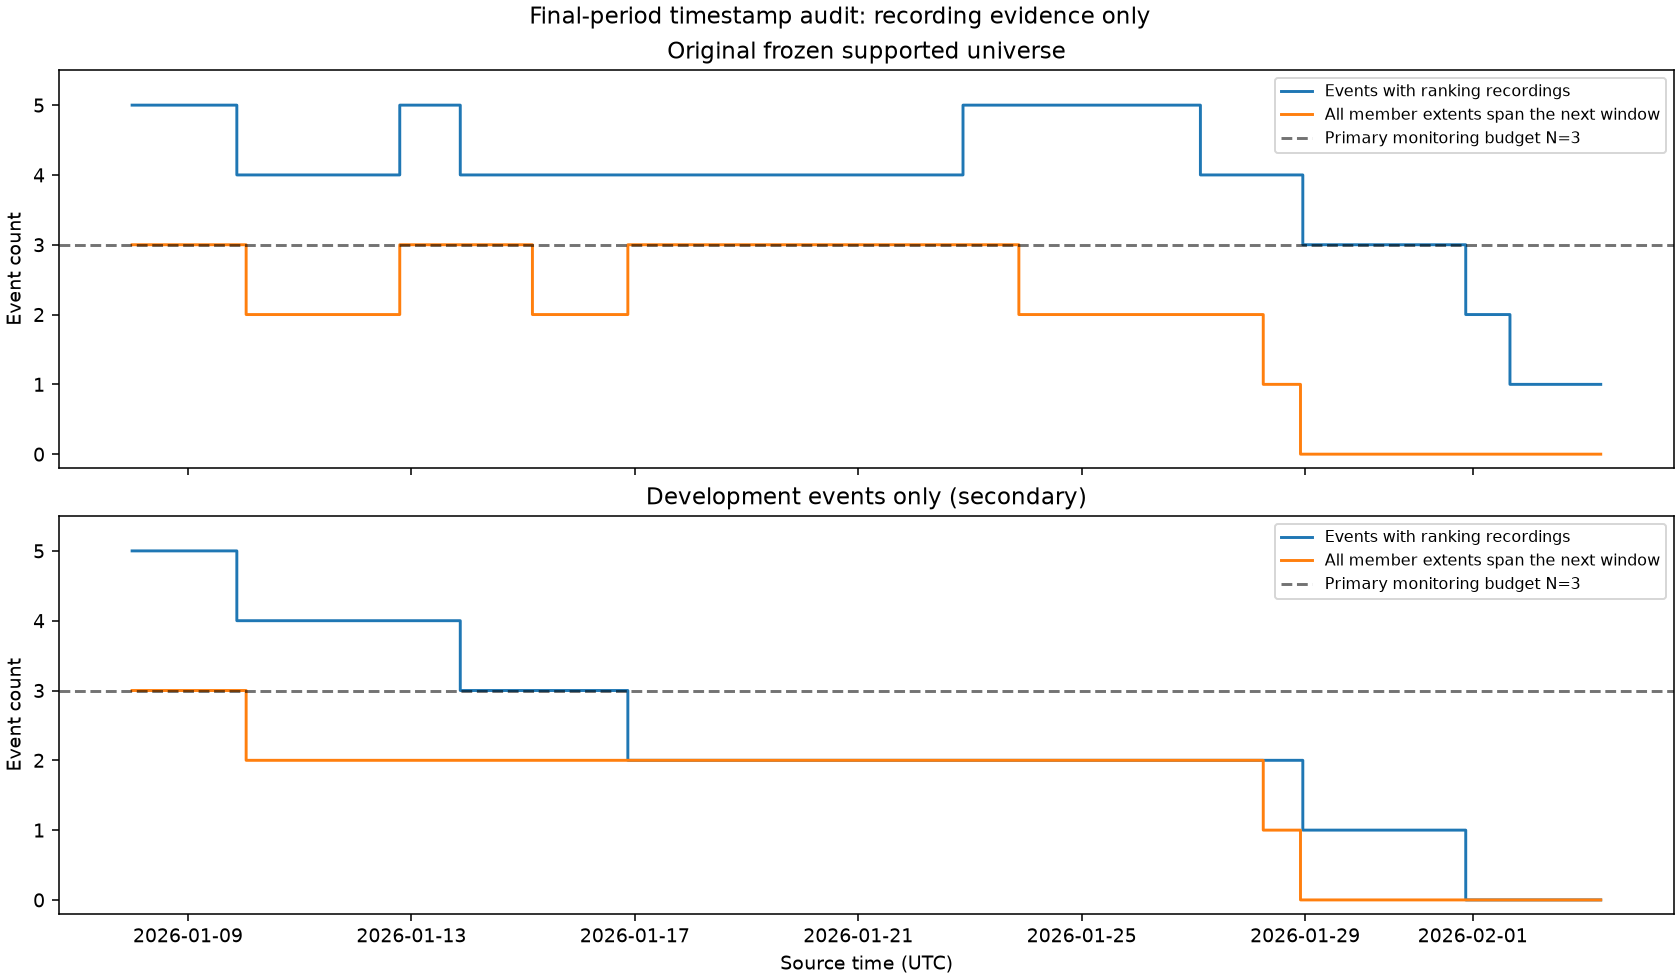

In [3]:
display(pd.DataFrame(summary['scopes']).T)
pool = pd.read_csv(AUDIT / 'hourly_pool.csv')
display(pool.groupby(['scope','eligible_events']).size().rename('hours').reset_index())
display(Image(filename=str(PROTOCOL / 'coverage.png')))

## Choices fixed before final outcomes

The primary value candidate is two-stage TabM, compared with quoted-gap on peak quoted-value capture@3. Fixed logistic is the occurrence reference. All saved policies remain in the comparison. No final-period tuning is allowed. The final tuned/fixed forests share one fitted artifact.

The primary economic scenario is 100 ms arrival, uncapped capital/shares, no random failure probability and a one-second partial unwind. Opportunity targets remain independent of execution outcomes. Random references and monitor-all are specified in the protocol.

In [4]:
display(pd.DataFrame([{'policy':name,'kind':entry['kind'],'feature_columns':len(entry['features'])}
                      for name,entry in protocol['policies'].items()]))
display(pd.Series(protocol['opportunity'], name='Opportunity evaluation'))
display(pd.Series(protocol['execution'], name='Frozen execution settings'))
print('Random seeds:', protocol['references']['random']['seeds'])
print('Arrival sensitivity:', protocol['latency_sensitivity_s'])

,policy,kind,feature_columns
0,quoted_gap_rule,rule,1
1,fixed_book_logistic,classifier,33
2,n3_book_logistic,classifier,33
3,fixed_book_random_forest,classifier,33
4,n3_book_random_forest,classifier,33
5,n3_tabm_two_stage,hurdle_ensemble,36


primary_model                                           n3_tabm_two_stage
primary_metric                                        peak_value_recall@3
primary_comparator                                        quoted_gap_rule
occurrence_reference                                  fixed_book_logistic
secondary_metrics       [opportunity recall, known precision, average ...
target                  Largest qualifying displayed dollar margin of ...
qualification           Same uncapped integer-depth quote qualificatio...
unknowns                Rank before labels. Unknown rows consume slots...
zero_denominators       Undefined capture/precision/AP remain missing ...
Name: Opportunity evaluation, dtype: object

wait_s                         0.0
delay_s                        0.1
sizing                    adaptive
min_entry_gross_usd            0.0
freshness_s                   None
max_quantity                  None
cash_cap_usd                  None
unwind_delay_s                 1.0
min_quantity                     5
min_limit_margin_usd           0.0
monitoring_minutes              60
compute_failure_stress       False
Name: Frozen execution settings, dtype: object

Random seeds: [20261001, 20261002, 20261003, 20261004, 20261005, 20261006, 20261007, 20261008, 20261009, 20261010, 20261011, 20261012, 20261013, 20261014, 20261015, 20261016, 20261017, 20261018, 20261019, 20261020]
Arrival sensitivity: [0.0, 0.05, 0.1, 0.25, 0.5]


## Next implementation boundary

The audit and protocol are complete; final feature/label construction, inference and replay require a separate explicit final-only runner. Historical development readers and their guards remain unchanged. Use Jan7's previous scheduled snapshot as feature context, never a future update. Verify whole raw files before evaluation and disclose unknown labels and exits. The protocol's source and artifact hashes make later revisions visible.

In [5]:
print('Protocol file:', PROTOCOL / 'protocol.json')
print('Audit read columns:', json.loads((AUDIT / 'design.json').read_text())['row_columns_read'])
print('Prepared model files frozen:', len(protocol['integrity']['final_model_files_sha256']))
print('Evaluation runner:', protocol['evaluation_runner'])
print('No final opportunities, predictions or P&L were calculated in this notebook.')

Protocol file: C:\Users\Daron\coding\inefficiency-prediction\results\final_protocol\protocol.json
Audit read columns: ['snapshot_time']
Prepared model files frozen: 10
Evaluation runner: Not executed or implemented by this audit. Implement as a separate explicit final-only path; preserve development access guards.
No final opportunities, predictions or P&L were calculated in this notebook.
